## Coloured Noise Modelling

Based on this Paper
https://ieeexplore.ieee.org/document/381848

$1/f^\alpha$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve
from scipy._lib._util import check_random_state
from scipy.optimize import nnls


In [3]:
def generate_noise(alpha, shape, dt=1.0, scale=1.0, rng=None):    
    # https://ieeexplore.ieee.org/document/381848
    rng = check_random_state(rng)
    shape = np.atleast_1d(shape)
    n_samples = shape[0]
    h = np.empty(n_samples)
    h[0] = 1
    for i in range(1, n_samples):
        h[i] = h[i - 1] * (0.5 * alpha + i - 1) / i
    h = h.reshape((-1,) + (1,) * (len(shape) - 1))
    
    # generate gaussian noise
    w = rng.randn(*shape)
    
    return scale * dt ** (-0.5 * (1 - alpha)) * fftconvolve(h, w)[:n_samples]


# coloured noise = (memory filter) convolved with (white noise)

In [4]:
def _compute_cluster_sizes(n_samples, dt, tau_min, tau_max, n_clusters):
    if tau_min is None:
        min_size = 1
    else:
        min_size = int(tau_min / dt)

    if tau_max is None:
        max_size = n_samples // 10
    else:
        max_size = int(tau_max / dt)

    result = np.logspace(np.log2(min_size), np.log2(max_size),
                         num=n_clusters, base=2)

    return np.unique(np.round(result)).astype(int)


def compute_avar(x, dt=1, tau_min=None, tau_max=None,
                 n_clusters=100, input_type='mean'):
    """Compute Allan variance (AVAR).

    Consider an underlying measurement y(t). Our sensors output integrals of
    y(t) over successive time intervals of length dt. These measurements
    x(k * dt) form the input to this function.

    Allan variance is defined for different averaging times tau = m * dt as
    follows::

        AVAR(tau) = 1/2 * <(Y(k + m) - Y(k))>,

    where Y(j) is the time average value of y(t) over [k * dt, (k + m) * dt]
    (call it a cluster), and < ... > means averaging over different clusters.
    If we define X(j) being an integral of x(s) from 0 to dt * j,
    we can rewrite the AVAR as  follows::

        AVAR(tau) = 1/(2 * tau**2) * <X(k + 2 * m) - 2 * X(k + m) + X(k)>

    We implement < ... > by averaging over different clusters of a given sample
    with overlapping, and X(j) is readily available from x.

    Parameters
    ----------
    x : ndarray, shape (n, ...)
        Sensor readings, interpretation depends on `input_type` argument.
        Assumed to vary along the 0-th axis.
    dt : float, optional
        Sampling period. Default is 1.
    tau_min : float or None, optional
        Minimum averaging time to use. If None (default), it is assigned equal
        to `dt`.
    tau_max : float or None, optional
        Maximum averaging time to use. If None (default), it is chosen
        automatically such that to averaging is done over 10 *independent*
        clusters.
    n_clusters : int, optional
        Number of clusters to compute Allan variance for. The averaging times
        will be spread approximately uniform in a log scale. Default is 100.
    input_type : {'mean', 'increment', 'integral'}, optional
        How to interpret the input data:

            - 'mean': `x` is assumed to contain mean values of y over
              successive time intervals.
            - 'increment': `x` is assumed to contain integral increments over
              successive time intervals.
            - 'integral': `x` is assumed to contain cumulative integral of
              y from the time start.

        Note that 'mean' can be used when passing filtered and sampled value
        of y. But in this case generally the filtering process affects
        properties of the underlying signal y and "effective" Allan variance
        is computed, i.e. you can use obtained parameters when working with
        the sampled signal.

    Returns
    -------
    tau : ndarray
        Averaging times for which Allan variance was computed, 1-d array.
    avar : ndarray
        Values of AVAR. The 0-th dimension is the same as for `tau`. The
        trailing dimensions match ones for `x`.

    References
    ----------
    .. [1] https://en.wikipedia.org/wiki/Allan_variance
    """
    ALLOWED_INPUT_TYPES = ['mean', 'increment', 'integral']

    if input_type not in ALLOWED_INPUT_TYPES:
        raise ValueError("`input_type` must be one of {}."
                         .format(ALLOWED_INPUT_TYPES))

    x = np.asarray(x, dtype=float)
    if input_type == 'integral':
        X = x
    else:
        X = np.cumsum(x, axis=0)

    cluster_sizes = _compute_cluster_sizes(len(x), dt, tau_min, tau_max,
                                           n_clusters)

    avar = np.empty(cluster_sizes.shape + X.shape[1:])
    for i, k in enumerate(cluster_sizes):
        c = X[2*k:] - 2 * X[k:-k] + X[:-2*k]
        avar[i] = np.mean(c**2, axis=0) / k / k

    if input_type == 'mean':
        avar *= 0.5
    else:
        avar *= 0.5 / dt**2

    return cluster_sizes * dt, avar

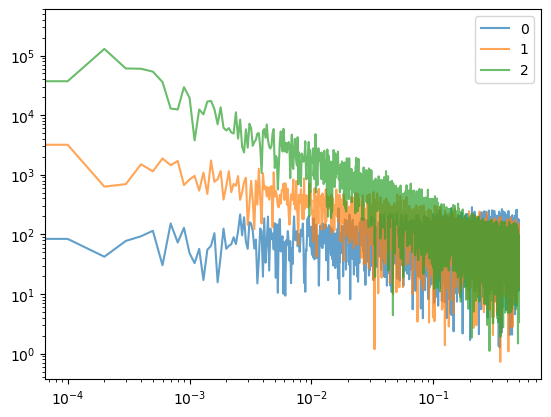

In [5]:
plt.figure()
for alph in [0,1,2]:
    n = 10000
    noise = generate_noise(alph,n)
    ffts = np.abs(np.fft.fft(noise))[:n//2]
    fs = np.fft.fftfreq(n)[:n//2]
    plt.loglog(fs, ffts, alpha = 0.7)
plt.legend([0,1,2])

# Coloured Noise

- Pure white noise is for a system that has no memory whatsoever
- Couloured noise exists because the measurement system "has memory", for example, a transistor holds charge throughout the measurement
- 1/f noise is what happens when you get many different decay periods overlapped with one another
- if accelerometers behave like mechanical oscillators (Springs) it's obvious that they have memory. The next timestamp relates to the last.

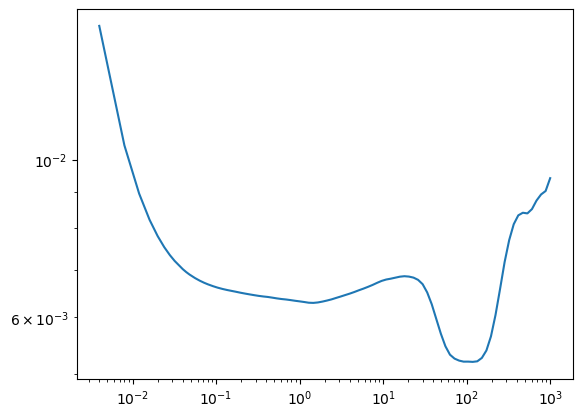

In [7]:
rate = 250 # Hz
dur = 6000 # s
dt = 1 / rate
n = int(dur / dt)
noise = generate_noise(0, n, dt, 0.005) + generate_noise(1, n, dt, 0.12) + generate_noise(1.8, n, dt, 0.001)

taus, avars = compute_avar(noise, dt, tau_max=1e3)
plt.loglog(taus, avars)

# Generate time series from offset specification
- https://doi.org/10.1109/4.826814
- https://doi.org/10.1109/4.658619
- https://doi.org/10.1109/TCSI.2006.881184
- https://arxiv.org/pdf/2104.07264

In [8]:
import numpy as np
from scipy.interpolate import interp1d

def generate_phase_noise_time_series(offsets, l_dbc, fs=1e6, duration=0.01, seed=42):
    np.random.seed(seed)
    N = int(fs * duration)
    if N % 2 == 1:
        N += 1
    t = np.arange(N) / fs
    df = fs / N
    freqs = np.arange(0, fs/2 + df, df)          # positive frequencies only
    
    # Interpolate L(f) in log-log domain... noise power
    f_interp = interp1d(np.log10(offsets), l_dbc, kind='linear', fill_value='extrapolate')
    L_interp = f_interp(np.log10(freqs[1:]))
    
    # Phase PSD (one-sided → properly scaled)
    S_phi = np.zeros_like(freqs)
    S_phi[1:] = 2 * 10**(L_interp / 10.0)        # rad²/Hz
    
    # Generate and shape noise
    noise_freq = (np.random.randn(len(freqs)) + 1j * np.random.randn(len(freqs))) / np.sqrt(2.0)   # gaussian noise
    noise_freq *= np.sqrt(S_phi * fs)                                                              # shape with ssb shape
    
    # Hermitian symmetry for real-valued output
    noise_full = np.concatenate([noise_freq, np.conj(noise_freq[-2:0:-1])])
    phi_t = np.real(np.fft.ifft(noise_full) * np.sqrt(N))
    
    return t, phi_t[:int(fs*duration)], freqs, S_phi

# Example usage with a placeholder profile
offsets = np.array([10, 100, 1000, 10000, 1e5, 1e6])
l_dbc   = np.array([-50, -75, -95, -115, -130, -140])

t, phi, freqs, S_phi = generate_phase_noise_time_series(offsets, l_dbc, fs=1e6, duration=0.01)

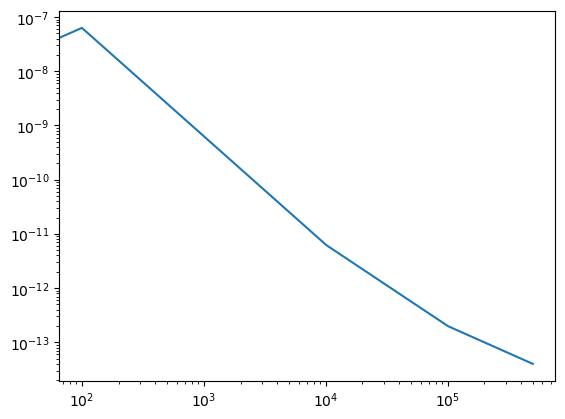

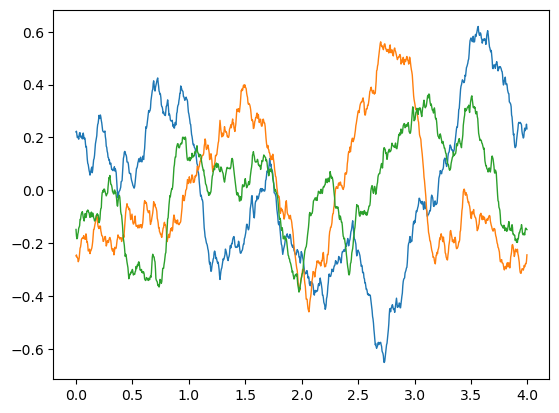

In [9]:
plt.loglog(freqs, S_phi)
plt.figure()
for i in range(3):
    t, phi_t = generate_phase_noise_time_series(offsets, l_dbc, fs=250, duration=4, seed = 123+i)[:2]
    plt.plot(t, phi_t, linewidth = 1)

# Other reading
- https://www.youtube.com/watch?v=wByzymJ0Ppc
- https://www.researchgate.net/publication/3094132_Analysis_and_Modeling_of_Inertial_Sensors_Using_Allan_Variance
- https://www.researchgate.net/publication/266439187_Stochastic_Modeling_of_MEMS_Inertial_Sensors <----
- https://scispace.com/pdf/stochastic-modelling-and-analysis-of-imu-sensor-errors-3mys6mjgcs.pdf
- http://www.instk.org/web/static/bibliography/Introduction_to_Sensor_Errors.pdf
- https://doi.org/10.1109/IEEESTD.1998.86153 (IEEE Standard for characterising IFOG gyro noise)

# Reading Notes
- Petkov & Slavov, 2010
  - pwlech in CRAPLAB generates the SSB PSD
  - 3 types of noise based on SSB slopes: bias instab, angular random walk (RW), and rate RW.
  - Mean square values B (f^-1), N (f^0), K (f^-2) respectively
  - neg discret err
  - They fit the values for B, N, K

- Analogies:
  - K is the daily weather
  - B is your heating system
  - N is measurement noise

- Angular random walk is just basic white noise.
- Bias instability: modeled as first order Gauss-Markov process:


  $\dot{b} - \frac{1}{\tau} b + w(t)$


  where $w(t)$ is  Gaussian white noise


- Autocorrelation $R_b(\tau) = \sigma_b^2 e^{-|\tau| / \tau_c}$

- RRW component is (completely uncorrelated?) white noise component.

- This does indeed assume that each of the 3 components is uncorrelated... But there is still correlation within each component.

In [10]:
# Section C of https://doi.org/10.1109/IEEESTD.1998.86153
# ADIS16350 datasheet https://www.analog.com/media/en/technical-documentation/data-sheets/ADIS16350_16355.pdf

d2r = np.deg2rad(1.0)
r2d = np.rad2deg(1.0)

# PSD Contributions
f0 = 100         # cut-off freq           (Hz)              # Taken straight from the datasheet 3dB BW
N = d2r*5.75e-2  # angle RW coeff         (deg/sqrt(s))     # 0.07 deg/rt(s) on datasheet 4.2 deg/sqrt(hr) "angular random walk"
B = d2r*1.55e-2  # bias instability coeff (deg/s)           # 0.015 deg/s on datasheet "in run bias stability"
K = d2r*9e-4     # Rate RW coeff          (deg/sqrt(s))     # 0.05 deg/rt(s) "rate noise density RMS"

S_arw = lambda f: np.ones_like(f)*N**2
S_bias = lambda f: f**(-1)*B**2/(2*np.pi)* (f < f0)
S_rrw = lambda f: f**(-2)*(K / 2*np.pi)**2


In [11]:
fs = 10**np.linspace(-4,2, 100)
SSB = 2 * (S_arw(fs) + S_bias(fs) + S_rrw(fs))

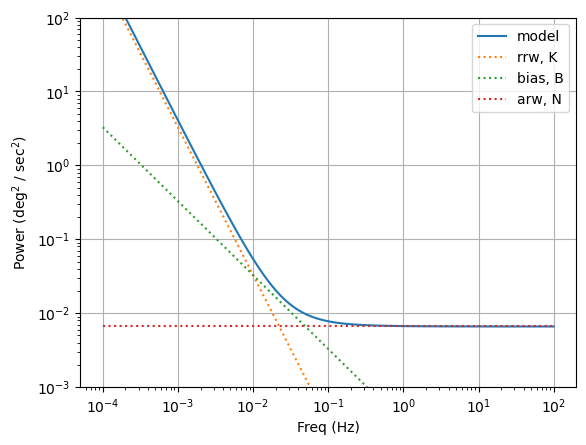

In [12]:
# plt.figure()
# plt.loglog(fs, 2*S_rrw(fs))
# plt.loglog(fs, 2*S_bias(fs))
# plt.loglog(fs, 2*S_arw(fs))

rsq2dsq = r2d**2 ## convert plot to degrees squared per second square

plt.figure()
plt.loglog(fs, rsq2dsq*SSB)
plt.grid()
plt.xlabel("Freq (Hz)")
plt.ylabel("Power (deg$^{2}$ / sec$^{2}$)")

# plot guides
plt.loglog(fs, rsq2dsq*10**np.log10(fs**-2) / 1e9, ':')
plt.loglog(fs, rsq2dsq*(fs**-1)/1e7, ':')
plt.loglog(fs, rsq2dsq*2*S_arw(fs), ':')
plt.ylim(1e-3,1e2)
plt.legend(["model", "rrw, K", "bias, B", "arw, N"])

In [13]:
np.sqrt((0.581614**2 - r2d*B**2 - r2d*K**2))

np.float64(0.5816103830790035)

In [14]:
sig_gyro = 0.581614
sig_arw = 0.581188
sig_x = 1.55e-2

In [15]:
sig_rrw = np.sqrt(sig_gyro**2 - sig_x**2 - sig_arw**2)

In [16]:
sig_rrw

np.float64(0.015971964562943808)

In [17]:
r2d*K

np.float64(0.0008999999999999999)

In [18]:
np.sqrt(-0.581614**2 - B**2 - 0.581188**2)

C:\Users\myriad\AppData\Local\Temp\ipykernel_26232\1515732854.py:1: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(-0.581614**2 - B**2 - 0.581188**2)


np.float64(nan)